## EDA Workflow & Visualization — Ames Housing

## Part A — run the first-30-minutes checklist

## TASK 01 Understand the data before any charts

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


# Load the dataset
df = pd.read_csv("ames_housing.csv")

# 1. Dataset shape
print("Dataset Shape (rows, columns):", df.shape)

# 2. First five rows
print("\nFirst Five Rows:")
display(df.head())

# 3. Dataset information 
print("\nDataset Information:")
df.info()

# 4. Descriptive statistics
print("\nDescriptive Statistics:")
display(df.describe().round(0))

# 5. COUNT houses in each neighborhood
print("\nDescriptive Statistics:")
display(df.describe().round(0))

# 6. Find missing values
missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0]

print("\nMissing Value Counts:")
display(missing_counts)

# 7. Calculate missing-value fractions
missing_fractions = df.isnull().mean()
missing_fractions = missing_fractions[missing_fractions > 0]

print("\nMissing Values Fraction:")
display(missing_fractions)


# 8. Visualize missing values
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values Map")
plt.xlabel("Column")
plt.show()

# 9. Check suspicious numerical value
print("\nNumerical Summary for Checking Outliers:")
display(df.describe().round(0))

# 10. SalePrice range and typical value
minimum_sale_price = df["SalePrice"].min()
maximum_sale_price = df["SalePrice"].max()
average_sale_price = df["SalePrice"].mean()
median_sale_price = df["SalePrice"].median()

print("\nSalePrice Analysis:")
print(f"Minimum SalePrice: {minimum_sale_price:,.0f}")
print(f"Maximum SalePrice: {maximum_sale_price:,.0f}")
print(f"Mean SalePrice: {average_sale_price:,.0f}")
print(f"Median SalePrice: {median_sale_price:,.0f}")

print(
    f"\nSalePrice ranges from {minimum_sale_price:,.0f} "
    f"to {maximum_sale_price:,.0f}."
)
print(f"The typical SalePrice (median) is {median_sale_price:,.0f}.")


1\. Why run the checklist every time?

 To identify missing values, incorrect data types, duplicates, and unexpected values before analysis.

2\. What is the danger of modeling without EDA?

The model may produce inaccurate predictions because of poor-quality data or hidden data issues.

3\. Mean much higher than median — what does it tell you?

 The data may be right-skewed, with a few unusually large values pulling the mean upward.

## Part B — 10+ visualizations telling a story (the deliverable)

## TASK 02 Univariate — each variable's own shape

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Load the dataset
df = pd.read_csv("ames_housing.csv")

sns.set_theme(style="whitegrid")

# 1. SalesPrice distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="SalePrice",bins= 40, kde=True)
plt.title("Distribution of SalePrice")
plt.xlabel("Sale Prize")
plt.ylabel("Number of Houses")
plt.show()


# 2. GrLivArea distribution
plt.figure(figsize=(8, 5))
sns.histplot(data= df, x="GrLivArea", bins=40, kde=True)
plt.title("Distribution of Above-Ground Living Area")
plt.xlabel("Living Area (square feet)")
plt.ylabel("Number of Houses")
plt.show()


# 3. LotArea distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="LotArea", bins=40, kde=True)
plt.title("Distribution of Lot Area")
plt.xlabel("Lot Area (square feet)")
plt.ylabel("Number of Houses")
plt.show()

# 4. OverallQual count plot
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="OverallQual")
plt.title("House Count by Overall Quality")
plt.xlabel("Overall Quality Rating")
plt.ylabel("Number of Houses")
plt.show()


# 5. Print observations to help describe the distributions
for column_name in ["SalePrice", "GrLivArea", "LotArea"]:
    skewness = df[column_name].skew()
    print(f"{column_name} skewness: {skewness:.2f}")

    if skewness > 0.5:
        print("Observation: Right-skewed; high values may form a long right tail.")
    elif skewness < -0.5:
        print("Observation: Left-skewed; low values may form a long left tail.")
    else:
        print("Observation: Approximately symmetric or only mildly skewed.")

print("\nOverallQual counts:")
print(df["OverallQual"].value_counts().sort_index())


1\. Why does the shape of `SalePrice` matter before modeling? 

It helps identify skewness and outliers, which can affect model accuracy and suggest whether a transformation is useful.

2\. When is a histogram better than a boxplot, and vice versa?

 A histogram shows the distribution's shape; a boxplot summarizes the median, quartiles, and potential outliers.

3\. What does a long right tail on price mean in the real world?

 Most houses have lower or moderate prices, while a few houses are much more expensive.

## TASK 03 Bivariate — what drives price?

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Load the dataset
df = pd.read_csv("ames_housing.csv")

sns.set_theme(style="whitegrid")

# 1. Scatter plot: Living Area vs SalePrice
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", alpha=0.4)
plt.title("Living Area vs Sale Price")
plt.xlabel("Above-Ground Living Area (square feet)")
plt.ylabel("Sale Price")
plt.show()

print("Takeaway: Check whether SalePrice generally increases as GrLivArea increases.")
print("Look for points far away from the main upward pattern.")

# 2. Boxplot: SalePrice across OverallQual levels
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="OverallQual", y="SalePrice")
plt.title("Sale Price by Overall Quality")
plt.xlabel("Overall Quality Rating")
plt.ylabel("Sale Price")
plt.show()

print("Takeaway: Compare the medians to see whether higher quality is associated with higher prices.")

# 3. Boxplot: SalePrice by Neighborhood, sorted by median price
neighborhood_order = (
    df.groupby("Neighborhood")["SalePrice"]
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x="Neighborhood", y="SalePrice", order=neighborhood_order )
plt.title("Sale Price by Neighborhood (Sorted by Median Price)")
plt.xlabel("Neighborhood")
plt.ylabel("Sale Price")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("Takeaway: Neighborhoods are ordered from lowest to highest median SalePrice.")

# 4. Scatter plot: YearBuilt vs SalePrice
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="YearBuilt", y="SalePrice", alpha=0.4)
plt.title("Year Built vs Sale Price")
plt.xlabel("Year Built")
plt.ylabel("Sale Price")
plt.show()

print("Takeaway: Check whether newer houses tend to have higher SalePrice.")


1\. Why sort neighborhoods before plotting? 

Sorting by median `SalePrice` makes it easy to compare and rank neighborhoods from cheapest to most expensive.

2\. Scatter plot vs. boxplot — when to use each?

- Scatter plot: Shows the relationship between two numerical variables.
- Boxplot: Compares distributions, medians, and potential outliers across categories.

3\. Which is the stronger driver of price: size, quality, or location? 

Typically, quality and size show strong relationships with price, while location also matters. The strongest factor in your dataset should be confirmed using your charts and correlation analysis.

## TASK 04 Multivariate — the whole picture

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Load the dataset
df = pd.read_csv("ames_housing.csv")

# 1. Correlation heatmap of all numeric columns
numeric_data = df.select_dtypes(include="number").drop(columns=["Id"], errors="ignore")
correlation_matrix = numeric_data.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot = True, fmt=".2f", cmap= "RdBu_r", center= 0)
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()


# 2. Find the top 3 variables correlated with SalePrice
price_correlations = (
    correlation_matrix["SalePrice"]
    .drop("SalePrice")
    .sort_values(ascending=False)
)

print("Top 3 positive correlations with SalePrice:")
print(price_correlations.head(3))


# 3. Scatter plot: Living area vs price, coloured by quality
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", hue="OverallQual", palette="viridis", alpha=0.7)

plt.title("Living Area vs Sale Price by Overall Quality")
plt.xlabel("Above-Ground Living Area (square feet)")
plt.ylabel("Sale Price")
plt.legend(title="Overall Quality")
plt.tight_layout()
plt.show()

# 4. Interactive Plotly scatter plot
fig = px.scatter(
    df,
    x="GrLivArea",
    y="SalePrice",
    color="OverallQual",
    hover_data=["Neighborhood", "YearBuilt", "Bedrooms", "LotArea"],
    title="Interactive: Living Area vs Sale Price by Quality",
    labels={
        "GrLivArea": "Living Area (square feet)",
        "SalePrice": "Sale Price",
        "OverallQual": "Overall Quality"
    }
)

#fig.show()
fig.show(renderer="browser")

# 5. Print top 3 strongest correlations by absolute strength
top_three_drivers = (
    correlation_matrix["SalePrice"]
    .drop("SalePrice")
    .abs()
    .sort_values(ascending=False)
    .head(3)
)

print("\nTop 3 features by absolute correlation with SalePrice:")
for feature_name, correlation_strength in top_three_drivers.items():
    actual_correlation = correlation_matrix.loc[feature_name, "SalePrice"]
    print(f"{feature_name}: correlation = {actual_correlation:.2f}")


1\. Why is a correlation heatmap useful in EDA? 

It shows relationships between numerical variables at a glance and helps identify strong correlations.

2\. When is an interactive chart better than a static chart?

 When we need to zoom, hover for details, or explore individual data points.

3\. Does correlation prove causation?

 No. Correlation shows that variables move together, but it does not prove that one causes the other.

## Part C — outliers and the wider toolkit

## TASK 05 Hunt the outliers

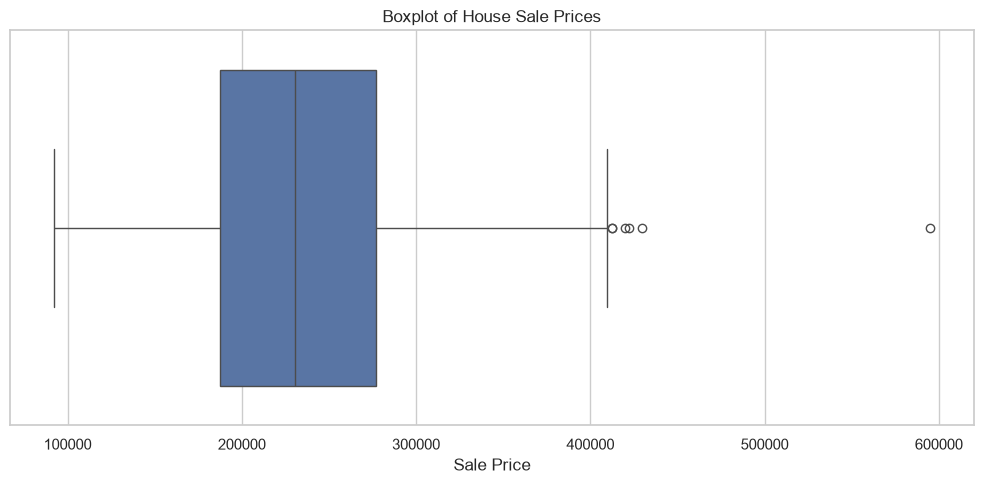

Q1: 187550.0
Q3: 276750.0
IQR: 89200.0
Lower limit: 53750.0
Upper limit: 410550.0
Number of price outliers: 6

Price outlier houses:
        Id  GrLivArea  OverallQual  SalePrice
319    320       1473            4     595000
810    811       2771            9     429800
844    845       2304            8     412300
1152  1153       2905           10     412200
1432  1433       2715           10     420000
1443  1444       2740           10     422400

Large houses with low sale prices:
        Id Neighborhood  GrLivArea  OverallQual  SalePrice
857    858       IDOTRR       4500            6     145000
1015  1016       Timber       4600            5     160000
Number of large, low-price houses: 2

Outlier assessment:
House ID 858: Area = 4500, Sale Price = 145000. Check the original records; it may be a genuine unusual sale or a data error. Do not remove it without verification.
House ID 1016: Area = 4600, Sale Price = 160000. Check the original records; it may be a genuine unusual sale

In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load your Ames Housing dataset
df = pd.read_csv("ames_housing.csv")

# 1. Boxplot of SalePrice to identify outliers
plt.figure(figsize=(10, 5))
sns.boxplot(x=df["SalePrice"])
plt.title("Boxplot of House Sale Prices")
plt.xlabel("Sale Price")
plt.tight_layout()
plt.show()


# 2. Identify price outliers using the IQR method
q1 = df["SalePrice"].quantile(0.25)
q3 = df["SalePrice"].quantile(0.75)
iqr = q3 - q1

lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

price_outliers = df[
    (df["SalePrice"] < lower_limit) |
    (df["SalePrice"] > upper_limit)
]

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of price outliers:", len(price_outliers))

print("\nPrice outlier houses:")
print(price_outliers[["Id", "GrLivArea", "OverallQual", "SalePrice"]])


# 3. Find unusually large houses with low sale prices
size_price_outliers = df[
    (df["GrLivArea"] > 4000) &
    (df["SalePrice"] < 200000)
]

print("\nLarge houses with low sale prices:")
print(size_price_outliers[
    ["Id", "Neighborhood", "GrLivArea", "OverallQual", "SalePrice"]
])

print("Number of large, low-price houses:", len(size_price_outliers))


# 4. Print a one-line assessment for each unusual house
print("\nOutlier assessment:")

for _, house in size_price_outliers.iterrows():
    print(
        f"House ID {house['Id']}: "
        f"Area = {house['GrLivArea']}, "
        f"Sale Price = {house['SalePrice']}. "
        "Check the original records; it may be a genuine unusual sale "
        "or a data error. Do not remove it without verification."
    )

1\. Why can a single outlier distort a model? \

It can pull the model toward an unusual value and reduce prediction accuracy.

2\. Should you always delete outliers? 

No. Keep genuine unusual cases; correct or remove only confirmed errors when justified.

3\. What is the difference between a univariate outlier and a relationship-breaking outlier?

 A univariate outlier is unusual in one variable. A relationship-breaking outlier does not follow the expected relationship between variables, such as a very large house with a surprisingly low sale price.

## TASK 06 Try plotnine (ggplot grammar)

In [39]:
import pandas as pd
from plotnine import ggplot, aes, geom_point, labs, theme_minimal

# Load your dataset
df = pd.read_csv("ames_housing.csv")

# Create a scatter plot
plot = (
    ggplot(df, aes(x="GrLivArea", y="SalePrice", color="OverallQual"))
    + geom_point(alpha=0.4)
    + labs(
        title="Living Area vs Sale Price",
        x="Living Area (square feet)",
        y="Sale Price",
        color="Overall Quality"
    )
    + theme_minimal()
)

print(plot)

<ggplot: (640 x 480)>
